# Caso 2 · Nodo Internet: predicción de bajas de clientes

**Equipo:** _completar nombres_

Este notebook sigue las consignas del enunciado (pasos 1 a 24). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.preparacion import agregar_variables, normalizar_metodo_pago
from src.knn import EscaladorEstandar, KNNClasificador
from src.negocio import SUPUESTOS, ganancia_campania, lift, mejor_umbral, probabilidad_de_equilibrio, resultado_por_contacto

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [ ]:
!python -m pytest -q --tb=no -rf

## Parte A · Exploración y preparación (`src/preparacion.py`)

**Paso 1.** Carguen `datos/clientes_historico.csv` e informen filas, tipos, nulos por columna, cuentas de empleados, tasa de baja y valores distintos de `metodo_pago`.

In [2]:
# Tu código aquí
df = pd.read_csv('datos/clientes_historico.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_cliente              20000 non-null  str    
 1   fecha_corte             20000 non-null  str    
 2   segmento                20000 non-null  str    
 3   fecha_alta              20000 non-null  str    
 4   edad_titular            20000 non-null  int64  
 5   zona                    20000 non-null  str    
 6   plan_mbps               20000 non-null  int64  
 7   tipo_contrato           20000 non-null  str    
 8   fin_permanencia         8509 non-null   str    
 9   tiene_tv                20000 non-null  str    
 10  metodo_pago             20000 non-null  str    
 11  dia_vencimiento         20000 non-null  int64  
 12  cargo_mensual_gs        20000 non-null  int64  
 13  uso_mensual_gb          19411 non-null  float64
 14  dispositivos_promedio   20000 non-null  int64  
 

In [4]:
df.head()

Out[4]: 
  id_cliente fecha_corte  ...  motivo_baja baja_90d
0  NI-118189  2026-05-31  ...          NaN        0
1  NI-119690  2026-05-31  ...  competencia        1
2  NI-113950  2026-05-31  ...          NaN        0
3  NI-118995  2026-05-31  ...          NaN        0
4  NI-112506  2026-05-31  ...          NaN        0

[5 rows x 23 columns]


### Total de empleados

In [5]:
df['segmento'].unique()

Out[5]: 
<StringArray>
['residencial', 'empleado']
Length: 2, dtype: str


In [6]:
total_empleados = (df['segmento'] == 'empleado').sum()
total_empleados

Out[6]: np.int64(612)


hay un total de 612 empleados

### Tasa de baja

In [7]:
tasa_bajas = df['baja_90d'].mean()
tasa_bajas

Out[7]: np.float64(0.07675)


La tasa de bajas es del 7.68%

### Valores distintos que figuran en metodo_pago

In [8]:
df['metodo_pago'].unique()

Out[8]: 
<StringArray>
[     'debito_automatico',          'transferencia',          'Transferencia',
               'efectivo',      'Debito_Automatico',        'tarjeta_credito',
 'transferencia bancaria',              'efectivo ',        'TARJETA CREDITO',
        'Tarjeta_Credito',      'DEBITO AUTOMATICO',               'EFECTIVO',
     'Tarjeta de crédito',          'TRANSFERENCIA',      'debito automatico',
               'Efectivo',        'tarjeta credito',      'Débito automático']
Length: 18, dtype: str


**Paso 2.** Implementen `normalizar_metodo_pago` y `agregar_variables` hasta que pasen `tests/test_preparacion.py`. Apliquen la función y excluyan las cuentas de empleados.

In [9]:
# Tu código aquí
df_clean = agregar_variables(df)

**Paso 3.** Tasa de baja por tipo de contrato, `sin_permanencia_3m`, zona, antigüedad, reclamos técnicos y consulta de baja web; zona este con cargo mayor a Gs. 280.000 contra el resto. Tres hallazgos para el negocio.

In [10]:

tasa_contrato = (
    df_clean.groupby('tipo_contrato')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_permanencia = (
    df_clean.groupby('sin_permanencia_3m')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_zona = (
    df_clean.groupby('zona')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_reclamos = (
    df_clean.groupby('reclamos_tecnicos_90d')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_web = (
    df_clean.groupby('consulto_baja_web_30d')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

In [11]:
df_clean['antiguedad_meses'].unique()

Out[11]: 
array([ 89.45466491,  29.89487516, 103.21944809, ...,  82.49014455,
        70.8935611 ,  90.24310118], shape=(3277,))


In [12]:

df_clean['tramo_antiguedad'] = pd.cut(
    df_clean['antiguedad_meses'],
    bins=[-1, 6, 12, 24, 48, np.inf],
    labels=[
        '0-6 meses',
        '6-12 meses',
        '12-24 meses',
        '24-48 meses',
        'Más de 48m',
    ],
)

tasa_antiguedad = (
    df_clean.groupby('tramo_antiguedad', observed=False)['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)


condicion_este_alto = (df_clean['zona'].str.lower() == 'este') & (
    df_clean['cargo_mensual_gs'] > 280000
)

df_clean['grupo_segmento'] = np.where(
    condicion_este_alto, 'Zona Este (>280k Gs)', 'Resto de Clientes'
)

tasa_segmento_especifico = (
    df_clean.groupby('grupo_segmento')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

In [13]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 28 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   id_cliente                   20000 non-null  str           
 1   fecha_corte                  20000 non-null  datetime64[us]
 2   segmento                     20000 non-null  str           
 3   fecha_alta                   20000 non-null  datetime64[us]
 4   edad_titular                 20000 non-null  int64         
 5   zona                         20000 non-null  str           
 6   plan_mbps                    20000 non-null  int64         
 7   tipo_contrato                20000 non-null  str           
 8   fin_permanencia              8509 non-null   datetime64[us]
 9   tiene_tv                     20000 non-null  str           
 10  metodo_pago                  20000 non-null  str           
 11  dia_vencimiento              20000 non-null  int64  

In [14]:
print('=== TASA DE BAJA POR TIPO DE CONTRATO ===\n', tasa_contrato, '\n')
print(
    '=== TASA DE BAJA POR SIN PERMANENCIA 3M ===\n', tasa_permanencia, '\n'
)
print('=== TASA DE BAJA POR ZONA ===\n', tasa_zona, '\n')
print('=== TASA DE BAJA POR ANTIGÜEDAD ===\n', tasa_antiguedad, '\n')
print('=== TASA DE BAJA POR RECLAMOS TÉCNICOS ===\n', tasa_reclamos, '\n')
print('=== TASA DE BAJA POR CONSULTA WEB BAJA ===\n', tasa_web, '\n')
print('=== SEGMENTO ZONA ESTE (>280K) VS RESTO ===\n', tasa_segmento_especifico)

=== TASA DE BAJA POR TIPO DE CONTRATO ===
                total_clientes  tasa_baja_pct
tipo_contrato                               
12_meses                 5753           5.28
24_meses                 2756           4.03
mensual                 11491           9.75 

=== TASA DE BAJA POR SIN PERMANENCIA 3M ===
                     total_clientes  tasa_baja_pct
sin_permanencia_3m                               
0                             6854           3.69
1                            13146           9.75 

=== TASA DE BAJA POR ZONA ===
         total_clientes  tasa_baja_pct
zona                                 
centro            3637           5.50
este              4051          14.93
norte             4381           5.46
oeste             3570           7.17
sur               4361           5.39 

=== TASA DE BAJA POR ANTIGÜEDAD ===
                   total_clientes  tasa_baja_pct
tramo_antiguedad                               
0-6 meses                   3294           8.74
6-1

**Paso 4.** Columnas que no pueden usarse como variables y por qué. Demuestren con una tabla el problema de la columna que haría parecer excelente a cualquier modelo.

In [15]:

tiene_motivo = df_clean['motivo_baja'].notna().map(
    {True: 'Tiene Motivo (Not NaN)', False: 'Sin Motivo (NaN)'}
)


tabla_leakage = pd.crosstab(
    tiene_motivo,
    df_clean['baja_90d'].map({1: 'Baja (1)', 0: 'Activo (0)'}),
    margins=True,
    margins_name='Total',
)

print(tabla_leakage)

baja_90d                Activo (0)  Baja (1)  Total
motivo_baja                                        
Sin Motivo (NaN)             18465         0  18465
Tiene Motivo (Not NaN)           0      1535   1535
Total                        18465      1535  20000


**Paso 5.** División 75/25 estratificada por `baja_90d` con `random_state=42`.

In [16]:
from sklearn.model_selection import train_test_split
import pandas as pd

columnas_a_excluir = [
    'baja_90d',
    'motivo_baja',
    'id_cliente',
    'fecha_corte',
    'fecha_alta',
    'fin_permanencia',
]

X = df_clean.drop(columns=columnas_a_excluir)
y = df_clean['baja_90d']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

## Parte B · Preprocesamiento y KNN desde cero (`src/knn.py`)

**Paso 6.** `ColumnTransformer`: imputación por mediana, `np.log1p` en `uso_mensual_gb` y `horas_sin_servicio_90d`, estandarización y `OneHotEncoder(handle_unknown="ignore")`.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)

cols_log = ['uso_mensual_gb', 'horas_sin_servicio_90d']
cols_categoricas = (
    X_train.select_dtypes(include=['object', 'string', 'category'])
    .columns.tolist()
)


cols_numericas = [
    col
    for col in X_train.columns
    if col not in cols_log and col not in cols_categoricas
]


pipeline_log = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='median')),
        ('log1p', FunctionTransformer(np.log1p, validate=True)),
        ('scaler', StandardScaler()),
    ]
)

pipeline_num = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

pipeline_cat = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='most_frequent')),
        (
            'encoder',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
        ),
    ]
)


preprocessor = ColumnTransformer(
    transformers=[
        ('num_log', pipeline_log, cols_log),
        ('num_std', pipeline_num, cols_numericas),
        ('cat_ohe', pipeline_cat, cols_categoricas),
    ],
    remainder='drop',
)


X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

**Paso 7.** Implementen `EscaladorEstandar` y `KNNClasificador` hasta que pasen `tests/test_knn.py`.

In [18]:
# Tu código aquí

**Paso 8.** Su `KNNClasificador` contra `KNeighborsClassifier` con k=51 y pesos por distancia: probabilidades iguales y tiempo de cada uno.

In [19]:
import time


from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    balanced_accuracy_score,
    confusion_matrix,
    matthews_corrcoef,
)


knn_propio = KNNClasificador(
    k=51,
    pesos="distancia",
    metrica="euclidea",
    tamano_lote=1000
)

knn_sklearn = KNeighborsClassifier(
    n_neighbors=51,
    weights="distance",
    metric="euclidean"
)

modelos = {
    "KNN Propio": knn_propio,
    "KNN Scikit-Learn": knn_sklearn,
}


resultados = []
probabilidades = {}
predicciones = {}

for nombre, modelo in modelos.items():

    t0 = time.perf_counter()
    modelo.fit(X_train_prep, y_train)
    tiempo_fit = time.perf_counter() - t0

    t0 = time.perf_counter()
    probas = modelo.predict_proba(X_test_prep)
    tiempo_predict = time.perf_counter() - t0


    probas_positivas = probas[:, 1]

    y_pred = (probas_positivas >= 0.5).astype(int)

    probabilidades[nombre] = probas
    predicciones[nombre] = y_pred

  
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()


    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probas_positivas
        ),
        "PR-AUC (AP)": average_precision_score(
            y_test, probas_positivas
        ),
        "Log Loss": log_loss(
            y_test, probas, labels=[0, 1]
        ),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Tiempo Fit (s)": tiempo_fit,
        "Tiempo Predict (s)": tiempo_predict,
        "Tiempo Total (s)": tiempo_fit + tiempo_predict,
    })



df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.set_index("Modelo")

print("=== COMPARACIÓN DE MÉTRICAS ===")
display(df_resultados.round(4).T)



probas_propio = probabilidades["KNN Propio"]
probas_sklearn = probabilidades["KNN Scikit-Learn"]

pred_propio = predicciones["KNN Propio"]
pred_sklearn = predicciones["KNN Scikit-Learn"]

son_iguales = np.allclose(
    probas_propio,
    probas_sklearn,
    atol=1e-5
)

diferencia_max = np.max(
    np.abs(probas_propio - probas_sklearn)
)

diferencia_media = np.mean(
    np.abs(probas_propio - probas_sklearn)
)

coincidencia_predicciones = np.mean(
    pred_propio == pred_sklearn
)

print("\n=== EQUIVALENCIA ===")
print(f"Probabilidades equivalentes : {son_iguales}")
print(f"Diferencia máxima absoluta  : {diferencia_max:.8f}")
print(f"Diferencia media absoluta   : {diferencia_media:.8f}")
print(f"Coincidencia predicciones   : {coincidencia_predicciones:.2%}")


t_propio = df_resultados.loc[
    "KNN Propio", "Tiempo Total (s)"
]

t_sklearn = df_resultados.loc[
    "KNN Scikit-Learn", "Tiempo Total (s)"
]

print("\n=== RENDIMIENTO ===")
print(f"Tiempo KNN Propio        : {t_propio:.4f} s")
print(f"Tiempo KNN Scikit-Learn  : {t_sklearn:.4f} s")
print(f"Factor tiempo            : {t_propio / t_sklearn:.2f}x")

Modelo,KNN Propio,KNN Scikit-Learn
Accuracy,0.9270,0.9270
Balanced Accuracy,0.5594,0.5594
Precision,0.6234,0.6234
Recall,0.1250,0.1250
F1,0.2082,0.2082
ROC-AUC,0.7857,0.7857
PR-AUC (AP),0.3605,0.3605
Log Loss,0.3470,0.3470
MCC,0.2567,0.2567
TN,4587.0000,4587.0000


=== COMPARACIÓN DE MÉTRICAS ===

=== EQUIVALENCIA ===
Probabilidades equivalentes : True
Diferencia máxima absoluta  : 0.00000000
Diferencia media absoluta   : 0.00000000
Coincidencia predicciones   : 100.00%

=== RENDIMIENTO ===
Tiempo KNN Propio        : 2.6349 s
Tiempo KNN Scikit-Learn  : 0.3564 s
Factor tiempo            : 7.39x


## Parte C · Ajuste de KNN

**Paso 9.** AP de KNN con k=25, con y sin estandarizar (validación cruzada estratificada de 5 particiones). Expliquen la diferencia.

In [20]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# Las dos variantes usan las mismas particiones y pesos por distancia,
# como en Paso 8. Solo cambia la estandarización de las numéricas.
cv_paso9 = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEMILLA
)
particiones_paso9 = list(cv_paso9.split(X_train, y_train))

preprocessor_sin_escalar = clone(preprocessor).set_params(
    num_log__scaler='passthrough',
    num_std__scaler='passthrough',
)

modelos_paso9 = {
    'Con estandarización': Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('knn', KNeighborsClassifier(
            n_neighbors=25, weights='distance', metric='euclidean'
        )),
    ]),
    'Sin estandarización': Pipeline([
        ('preprocessor', preprocessor_sin_escalar),
        ('knn', KNeighborsClassifier(
            n_neighbors=25, weights='distance', metric='euclidean'
        )),
    ]),
}

# El Pipeline ajusta imputación, escalado y one-hot dentro de cada fold.
# Se usa X_train original: la prueba final queda fuera de este ajuste.
ap_por_fold_paso9 = pd.DataFrame({
    nombre: cross_val_score(
        modelo, X_train, y_train, cv=particiones_paso9,
        scoring='average_precision', n_jobs=1, error_score='raise',
    )
    for nombre, modelo in modelos_paso9.items()
}, index=pd.Index(range(1, 6), name='Partición'))

resumen_paso9 = pd.DataFrame({
    'AP medio': ap_por_fold_paso9.mean(),
    'Desvío entre particiones': ap_por_fold_paso9.std(ddof=1),
})

display(ap_por_fold_paso9.round(4))
display(resumen_paso9.round(4))
print(f'AP de referencia (tasa de baja en entrenamiento): {y_train.mean():.4f}')
diferencia_ap_paso9 = (
    resumen_paso9.loc['Con estandarización', 'AP medio']
    - resumen_paso9.loc['Sin estandarización', 'AP medio']
)
print(f'Diferencia de AP (con - sin): {diferencia_ap_paso9:+.4f}')

,Con estandarización,Sin estandarización
Partición,,
1,0.3844,0.1320
2,0.4367,0.1548
3,0.3520,0.1484
4,0.3408,0.1410
5,0.3728,0.1540


,AP medio,Desvío entre particiones
Con estandarización,0.3773,0.0373
Sin estandarización,0.1460,0.0096


AP de referencia (tasa de baja en entrenamiento): 0.0767
Diferencia de AP (con - sin): +0.2313


**Interpretación del Paso 9.** Con k=25 y pesos por distancia, el AP medio es **0,3773 con estandarización** (desvío entre particiones: 0,0373) y **0,1460 sin estandarización** (desvío: 0,0096). La mejora es de **0,2313 puntos de AP** y se observa en las cinco particiones. Ambas variantes superan la referencia de la tasa de baja en entrenamiento (0,0767). AP evalúa la capacidad de ordenar a los clientes que se darán de baja por encima del resto; estos valores no son porcentajes de aciertos.

KNN determina los vecinos a partir de las distancias. Sin estandarizar, una variable como `cargo_mensual_gs`, expresada en cientos de miles, puede dominar la distancia euclídea frente a reclamos, antigüedad o indicadores binarios. Dos clientes pueden resultar vecinos por tener cargos similares aunque difieran en señales de riesgo. Al estandarizar las variables numéricas, sus diferencias se expresan en unidades de desvío estándar y esas señales pueden influir en la elección de los vecinos. En estos datos, esa elección mejora el ordenamiento del riesgo de baja.

La comparación conserva la imputación, `log1p` y la codificación one-hot; solo se retiran los dos escaladores en la segunda variante. Se reutilizan exactamente las mismas cinco particiones estratificadas y cada Pipeline aprende el preprocesamiento únicamente con el entrenamiento de su partición, evitando fuga de información. El conjunto de prueba final no se usa para calcular estos AP.

**Paso 10.** `GridSearchCV` con `average_precision`: k, pesos y `p`. Gráfico de AP en función de k y explicación del k elegido.

,k,pesos,p,AP medio,Desvío CV
0,801,Por distancia,1,0.4266,0.0168
1,1601,Por distancia,1,0.4258,0.0158
2,401,Por distancia,1,0.4247,0.0188
3,801,Uniformes,1,0.4220,0.0163
4,1601,Uniformes,1,0.4212,0.0160
5,401,Uniformes,1,0.4205,0.0174
6,201,Por distancia,1,0.4190,0.0189
7,101,Por distancia,1,0.4144,0.0234
8,201,Uniformes,1,0.4121,0.0176
9,51,Por distancia,1,0.4082,0.0238


Mejores parámetros: {'knn__n_neighbors': 801, 'knn__p': 1, 'knn__weights': 'distance'}
Mejor AP medio en validación: 0.4266


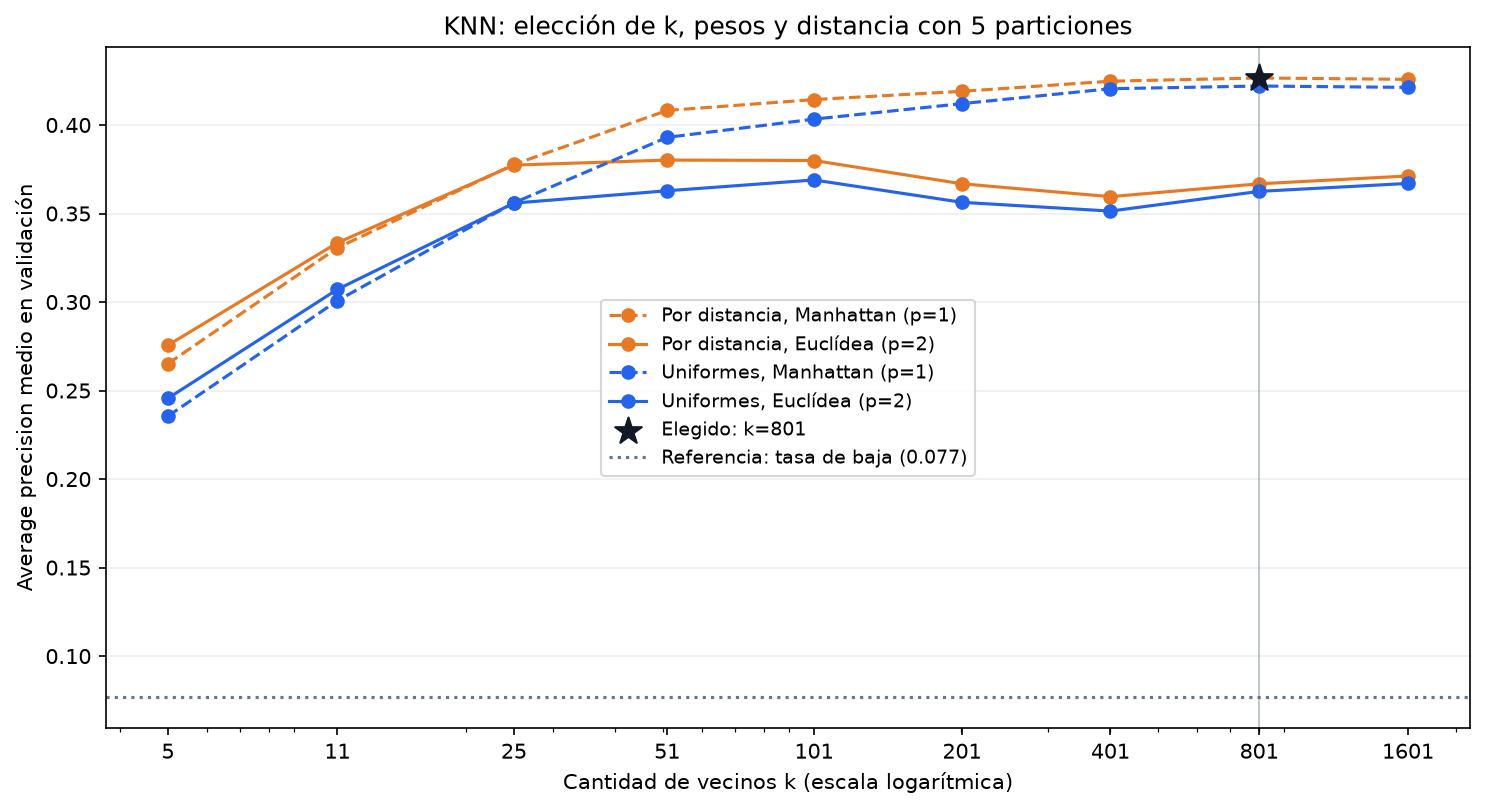

In [21]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

# Minkowski: p=1 es Manhattan y p=2 es euclídea.
valores_k = [5, 11, 25, 51, 101, 201, 401, 801, 1601]
grilla_knn = {
    'knn__n_neighbors': valores_k,
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}
pipeline_knn = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('knn', KNeighborsClassifier(metric='minkowski')),
])
cv_paso10 = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEMILLA
)

# Cada fold aprende su preprocesamiento. X_test no interviene.
busqueda_knn = GridSearchCV(
    pipeline_knn, grilla_knn, scoring='average_precision',
    cv=cv_paso10, refit=True, n_jobs=1, error_score='raise',
)
busqueda_knn.fit(X_train, y_train)
mejor_knn = busqueda_knn.best_estimator_

resultados_grid_knn = pd.DataFrame(busqueda_knn.cv_results_)
resultados_grid_knn['k'] = resultados_grid_knn[
    'param_knn__n_neighbors'
].astype(int)
resultados_grid_knn['pesos'] = resultados_grid_knn[
    'param_knn__weights'
].map({'uniform': 'Uniformes', 'distance': 'Por distancia'})
resultados_grid_knn['p'] = resultados_grid_knn['param_knn__p'].astype(int)

tabla_grid_knn = resultados_grid_knn[[
    'k', 'pesos', 'p', 'mean_test_score', 'std_test_score',
]].rename(columns={
    'mean_test_score': 'AP medio', 'std_test_score': 'Desvío CV',
}).sort_values('AP medio', ascending=False)
display(tabla_grid_knn.head(10).round(4).reset_index(drop=True))
print('Mejores parámetros:', busqueda_knn.best_params_)
print(f'Mejor AP medio en validación: {busqueda_knn.best_score_:.4f}')

mejor_fila_knn = resultados_grid_knn.loc[busqueda_knn.best_index_]
k_elegido = int(mejor_fila_knn['k'])
p_elegido = int(mejor_fila_knn['p'])
pesos_elegidos = mejor_fila_knn['pesos']

fig_paso10, ax_paso10 = plt.subplots(figsize=(10, 5.5))
colores_paso10 = {'Uniformes': '#2563eb', 'Por distancia': '#e87924'}
for (pesos, p), grupo in resultados_grid_knn.groupby(['pesos', 'p']):
    grupo = grupo.sort_values('k')
    metrica = 'Manhattan' if p == 1 else 'Euclídea'
    ax_paso10.plot(
        grupo['k'], grupo['mean_test_score'], marker='o',
        color=colores_paso10[pesos], linestyle='--' if p == 1 else '-',
        label=f'{pesos}, {metrica} (p={p})',
    )
ax_paso10.scatter(
    k_elegido, busqueda_knn.best_score_, s=180, marker='*',
    color='#111827', zorder=5, label=f'Elegido: k={k_elegido}',
)
ax_paso10.axvline(k_elegido, color='#64748b', alpha=0.4, linewidth=1)
ax_paso10.axhline(
    y_train.mean(), color='#64748b', linestyle=':',
    label=f'Referencia: tasa de baja ({y_train.mean():.3f})',
)
ax_paso10.set_xscale('log')
ax_paso10.set_xticks(valores_k, labels=[str(k) for k in valores_k])
ax_paso10.set_xlabel('Cantidad de vecinos k (escala logarítmica)')
ax_paso10.set_ylabel('Average precision medio en validación')
ax_paso10.set_title('KNN: elección de k, pesos y distancia con 5 particiones')
ax_paso10.grid(axis='y', alpha=0.2)
ax_paso10.legend(fontsize=9, loc='best')
fig_paso10.tight_layout()
plt.show()

**Elección del modelo.** Se evaluaron 36 combinaciones de nueve valores de k, dos tipos de pesos y dos valores de p, con cinco particiones estratificadas y `average_precision`. La combinación elegida es **k=801, pesos por distancia y p=1 (Manhattan)**, porque obtuvo el mayor AP medio de la grilla: **0,4266**, con un desvío entre particiones de **0,0168**. El Pipeline completo se reajusta sobre todo el entrenamiento y queda disponible como `mejor_knn`.

**Interpretación de la curva.** Con pocos vecinos, el AP es menor: las probabilidades dependen de un vecindario pequeño y son más sensibles al ruido. En la curva de Manhattan con pesos por distancia, el AP mejora al aumentar k y llega a una meseta: **0,4247 con k=401**, **0,4266 con k=801** y **0,4258 con k=1601**. Incorporar más vecinos suaviza las estimaciones, mientras los pesos por distancia mantienen mayor influencia de los clientes cercanos. La pequeña caída con k=1601 indica que aumentar k deja de aportar mejoras en esta grilla.

La ventaja de k=801 frente a k=401 es pequeña (aproximadamente 0,0018 de AP) respecto de la variación entre particiones; se elige por el criterio de máximo AP medio, sin afirmar una superioridad estadística. Manhattan supera a la distancia euclídea en la zona de mayor AP de esta grilla. El resultado respalda esta combinación para los datos y el preprocesamiento actuales, y deberá confirmarse en la evaluación final de prueba.

La búsqueda recibe `X_train` original y ajusta imputación, transformación logarítmica, estandarización y one-hot dentro de cada partición. Usa la misma configuración de particiones que Paso 9 y mantiene el conjunto de prueba final fuera de la selección.

**Paso 11.** AP sin las variables de permanencia y, por separado, sin `edad_titular`, `dispositivos_promedio` ni `dia_vencimiento`. Conclusión.

In [22]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

columnas_permanencia = [
    'tipo_contrato', 'meses_hasta_fin_permanencia', 'sin_permanencia_3m',
]
columnas_perfil = [
    'edad_titular', 'dispositivos_promedio', 'dia_vencimiento',
]
grupos_paso11 = {
    'Completo': [],
    'Sin permanencia': columnas_permanencia,
    'Sin edad, dispositivos ni vencimiento': columnas_perfil,
}

def crear_variante_knn(columnas_excluir):
    # clone elimina el ajuste previo y conserva los parámetros de Paso 10.
    modelo = clone(mejor_knn)
    prep = modelo.named_steps['preprocessor']
    transformadores = []
    for nombre, transformador, columnas in prep.transformers:
        restantes = [c for c in columnas if c not in columnas_excluir]
        if restantes:
            transformadores.append((nombre, transformador, restantes))
    prep.set_params(transformers=transformadores)
    return modelo

# Las mismas particiones y los mismos parámetros para las tres variantes.
particiones_paso11 = list(cv_paso10.split(X_train, y_train))
modelos_paso11 = {}
puntajes_paso11 = {}
for nombre, columnas_excluir in grupos_paso11.items():
    X_variante = X_train.drop(columns=columnas_excluir)
    modelo = crear_variante_knn(columnas_excluir)
    modelos_paso11[nombre] = modelo
    puntajes_paso11[nombre] = cross_val_score(
        modelo, X_variante, y_train, cv=particiones_paso11,
        scoring='average_precision', n_jobs=1, error_score='raise',
    )

ap_por_fold_paso11 = pd.DataFrame(
    puntajes_paso11, index=pd.Index(range(1, 6), name='Partición'),
)
# Diferencias pareadas: cada columna se compara con el completo del mismo fold.
deltas_por_fold_paso11 = ap_por_fold_paso11.subtract(
    ap_por_fold_paso11['Completo'], axis=0,
)
resumen_paso11 = pd.DataFrame({
    'Variables originales': {
        nombre: X_train.shape[1] - len(columnas)
        for nombre, columnas in grupos_paso11.items()
    },
    'AP medio': ap_por_fold_paso11.mean(),
    'Desvío entre particiones': ap_por_fold_paso11.std(ddof=1),
    'Cambio de AP frente al completo': deltas_por_fold_paso11.mean(),
})

parametros_paso11 = mejor_knn.named_steps['knn'].get_params()
print('Parámetros fijos:', {
    nombre: parametros_paso11[nombre]
    for nombre in ['n_neighbors', 'weights', 'p']
})
display(ap_por_fold_paso11.round(4))
display(resumen_paso11.round(4))
display(deltas_por_fold_paso11.round(4))

,Completo,Sin permanencia,"Sin edad, dispositivos ni vencimiento"
Partición,,,
1,0.4301,0.3611,0.4385
2,0.4524,0.3950,0.4467
3,0.4165,0.4016,0.4130
4,0.4021,0.3396,0.4038
5,0.4317,0.3807,0.4354


,Variables originales,AP medio,Desvío entre particiones,Cambio de AP frente al completo
Completo,22,0.4266,0.0188,0.0000
Sin permanencia,19,0.3756,0.0254,-0.0510
"Sin edad, dispositivos ni vencimiento",19,0.4275,0.0182,0.0009


,Completo,Sin permanencia,"Sin edad, dispositivos ni vencimiento"
Partición,,,
1,0.0,-0.0691,0.0084
2,0.0,-0.0574,-0.0058
3,0.0,-0.0149,-0.0035
4,0.0,-0.0625,0.0017
5,0.0,-0.0510,0.0037


Parámetros fijos: {'n_neighbors': 801, 'weights': 'distance', 'p': 1}


**Conclusión del Paso 11.** Con k=801, pesos por distancia y p=1, el KNN completo obtiene un AP medio de **0,4266**. Al quitar `tipo_contrato`, `meses_hasta_fin_permanencia` y `sin_permanencia_3m`, el AP baja a **0,3756** (cambio: **−0,0510**) y disminuye en las cinco particiones. Este grupo aporta información útil para ordenar el riesgo de baja en el modelo evaluado; conviene conservarlo.

Al quitar `edad_titular`, `dispositivos_promedio` y `dia_vencimiento`, el AP es **0,4275** (cambio: **+0,0009**). La diferencia es muy pequeña y tiene signos distintos entre particiones: mejora en tres y empeora en dos. La comparación sugiere que el aporte conjunto de estas variables es escaso para este KNN y que un modelo más simple podría obtener un rendimiento parecido; la diferencia observada no demuestra una mejora consistente.

Los parámetros se mantienen fijos para aislar el efecto de retirar variables y las exclusiones se hacen por separado. Cada variante aprende de nuevo el preprocesamiento y el KNN dentro de las mismas cinco particiones de entrenamiento. El desvío de la tabla usa ddof=1; el de GridSearchCV en Paso 10 usa ddof=0, por lo que difieren aunque el AP medio del modelo completo coincide. La comparación describe el rendimiento de estos grupos con la configuración elegida; no establece efectos causales de las variables sobre las bajas.

**Corrección de los datos.** Antes de concluir se corrigió `agregar_variables`: los meses restantes se calculan con `fin_permanencia - fecha_corte`, usando `DIAS_POR_MES`, en lugar de calcular la antigüedad. Se recalcularon las salidas y conclusiones de los pasos 9, 10 y 11; las 14 pruebas de preparación pasan.

## Parte D · Naive Bayes gaussiano como comparación

**Paso 12.** AP de `GaussianNB` con el mismo preprocesamiento, con y sin transformación logarítmica.

In [23]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB

# Misma imputación, estandarización y one-hot de KNN.
# Solo se retira log1p en la segunda variante; los escaladores se conservan.
particiones_paso12 = list(cv_paso10.split(X_train, y_train))
preprocessor_sin_log = clone(preprocessor).set_params(
    num_log__log1p='passthrough',
)
modelos_nb = {
    'GaussianNB con log1p': Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('nb', GaussianNB()),
    ]),
    'GaussianNB sin log1p': Pipeline([
        ('preprocessor', preprocessor_sin_log),
        ('nb', GaussianNB()),
    ]),
}

ap_por_fold_paso12 = pd.DataFrame({
    nombre: cross_val_score(
        modelo, X_train, y_train, cv=particiones_paso12,
        scoring='average_precision', n_jobs=1, error_score='raise',
    )
    for nombre, modelo in modelos_nb.items()
}, index=pd.Index(range(1, 6), name='Partición'))
# El KNN completo del Paso 11 usa estas mismas particiones.
ap_por_fold_paso12.insert(0, 'KNN elegido', ap_por_fold_paso11['Completo'])
resumen_paso12 = pd.DataFrame({
    'AP medio': ap_por_fold_paso12.mean(),
    'Desvío entre particiones': ap_por_fold_paso12.std(ddof=1),
})
display(ap_por_fold_paso12.round(4))
display(resumen_paso12.round(4))
delta_log_paso12 = (
    ap_por_fold_paso12['GaussianNB con log1p']
    - ap_por_fold_paso12['GaussianNB sin log1p']
)
print(f'Cambio de AP (con - sin log1p): {delta_log_paso12.mean():+.4f}')
print(f'AP de referencia (tasa de baja): {y_train.mean():.4f}')

# Se elige por AP medio de CV y se reajusta sobre todo el entrenamiento.
# Queda disponible para las siguientes partes, junto a mejor_knn.
nombre_mejor_nb = resumen_paso12.loc[list(modelos_nb), 'AP medio'].idxmax()
mejor_nb = clone(modelos_nb[nombre_mejor_nb]).fit(X_train, y_train)
print('Variante de Naive Bayes elegida:', nombre_mejor_nb)

,KNN elegido,GaussianNB con log1p,GaussianNB sin log1p
Partición,,,
1,0.4301,0.3545,0.3289
2,0.4524,0.3414,0.3324
3,0.4165,0.3804,0.3585
4,0.4021,0.3450,0.3448
5,0.4317,0.3743,0.3685


,AP medio,Desvío entre particiones
KNN elegido,0.4266,0.0188
GaussianNB con log1p,0.3591,0.0175
GaussianNB sin log1p,0.3466,0.0169


Cambio de AP (con - sin log1p): +0.0125
AP de referencia (tasa de baja): 0.0767
Variante de Naive Bayes elegida: GaussianNB con log1p


**Interpretación del Paso 12.** El AP medio es **0,3591 con `log1p`** (desvío: 0,0175) y **0,3466 sin `log1p`** (desvío: 0,0169). La transformación mejora el AP en **0,0125**, con diferencias positivas en las cinco particiones. Se conserva la variante con `log1p` como `mejor_nb`. Ambas superan la referencia de prevalencia (0,0767), pero quedan por debajo del **KNN elegido: 0,4266** (desvío: 0,0188). AP mide el ordenamiento del riesgo, no el porcentaje de aciertos. Todos los desvíos de esta tabla usan ddof=1.

`log1p` comprime los valores altos de uso y horas sin servicio y puede acercar distribuciones asimétricas a la forma gaussiana; la mejora observada no demuestra normalidad. GaussianNB estima una media y una varianza por variable y clase. La estandarización no es necesaria para equilibrar distancias, aunque se conserva para cumplir la comparación con el mismo preprocesamiento. Las variables binarias de one-hot tampoco tienen distribución gaussiana: este modelo sirve como referencia bajo una aproximación. Véase la [documentación de GaussianNB](https://scikit-learn.org/stable/modules/naive_bayes.html#gaussian-naive-bayes).

Cada Pipeline aprende imputación, transformación, escalado y categorías dentro del entrenamiento de cada partición; la Parte D usa únicamente `X_train` y `y_train`.

**Paso 13.** Correlación de Spearman entre las variables de calidad del servicio y relación con el supuesto de independencia.

,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m
velocidad_medida_pct,1.000,-0.229,-0.352,-0.280
horas_sin_servicio_90d,-0.229,1.000,0.283,0.098
reclamos_tecnicos_90d,-0.352,0.283,1.000,0.151
visitas_tecnicas_12m,-0.280,0.098,0.151,1.000


,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m
velocidad_medida_pct,1.000,-0.214,-0.331,-0.268
horas_sin_servicio_90d,-0.214,1.000,0.264,0.092
reclamos_tecnicos_90d,-0.331,0.264,1.000,0.137
visitas_tecnicas_12m,-0.268,0.092,0.137,1.000


,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m
velocidad_medida_pct,1.000,-0.317,-0.449,-0.377
horas_sin_servicio_90d,-0.317,1.000,0.425,0.128
reclamos_tecnicos_90d,-0.449,0.425,1.000,0.240
visitas_tecnicas_12m,-0.377,0.128,0.240,1.000


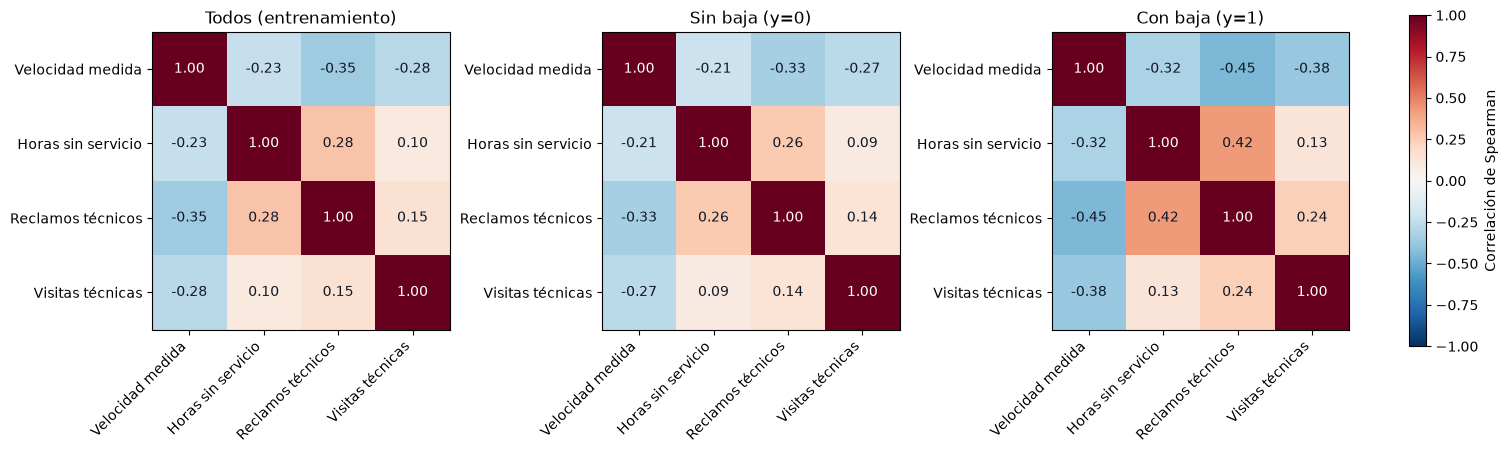

In [24]:
from pathlib import Path

cols_calidad_servicio = [
    'velocidad_medida_pct', 'horas_sin_servicio_90d',
    'reclamos_tecnicos_90d', 'visitas_tecnicas_12m',
]
# Spearman se calcula sobre valores originales, con pares no nulos.
# La independencia que supone NB es CONDICIONAL a la clase:
# también examinamos las correlaciones dentro de cada valor de baja_90d.
correlaciones_spearman = {
    'Todos (entrenamiento)': X_train[cols_calidad_servicio].corr(method='spearman'),
    'Sin baja (y=0)': X_train.loc[y_train == 0, cols_calidad_servicio].corr(method='spearman'),
    'Con baja (y=1)': X_train.loc[y_train == 1, cols_calidad_servicio].corr(method='spearman'),
}
etiquetas_calidad = ['Velocidad medida', 'Horas sin servicio', 'Reclamos técnicos', 'Visitas técnicas']
fig_paso13, axes_paso13 = plt.subplots(1, 3, figsize=(15, 5), layout='constrained')
for ax, (nombre, corr) in zip(axes_paso13, correlaciones_spearman.items()):
    display(corr.round(3))
    imagen = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(4), etiquetas_calidad, rotation=45, ha='right')
    ax.set_yticks(range(4), etiquetas_calidad)
    ax.set_title(nombre)
    for fila in range(4):
        for columna in range(4):
            valor = corr.iloc[fila, columna]
            ax.text(columna, fila, f'{valor:.2f}', ha='center', va='center',
                    color='white' if abs(valor) > 0.65 else '#111827')
fig_paso13.colorbar(imagen, ax=axes_paso13, shrink=0.75, label='Correlación de Spearman')
Path('figuras').mkdir(exist_ok=True)
fig_paso13.savefig('figuras/paso13_spearman_servicio.png', dpi=160, bbox_inches='tight')
plt.show()

**Interpretación del Paso 13.** En entrenamiento, la velocidad medida se correlaciona negativamente con reclamos técnicos (**−0,352**), visitas técnicas (**−0,280**) y horas sin servicio (**−0,229**). Las horas sin servicio se correlacionan positivamente con los reclamos (**0,283**). Estas variables contienen señales relacionadas sobre la calidad del servicio.

Naive Bayes supone independencia **dada la clase**, por lo que una correlación global no alcanza para evaluar ese supuesto. Las asociaciones también aparecen dentro de cada clase: velocidad y reclamos presentan **−0,331 entre quienes no se dieron de baja** y **−0,449 entre quienes sí**, mientras horas sin servicio y reclamos presentan **0,264** y **0,425**, respectivamente. Esto aporta evidencia contra la independencia condicional: multiplicar las verosimilitudes de señales relacionadas puede contabilizar repetidamente información parecida y producir probabilidades demasiado extremas.

Spearman describe asociación monótona, no causalidad, y una correlación cercana a cero no demuestra independencia. Se usan las variables originales y pares de observaciones no nulas; no se imputa para este análisis descriptivo. La codificación one-hot también crea dependencias entre indicadores de una misma categoría.

**Paso 14.** Probabilidades fuera de muestra de los dos modelos: puntaje de Brier e histogramas. ¿Cuál exagera más su confianza?

Modelo,KNN elegido,GaussianNB con log1p
Brier OOF (menor es mejor),0.0644,0.1655
AP OOF,0.4227,0.3526
Probabilidad media,0.0490,0.2445
"Fracción p <= 0,05",0.6882,0.5341
"Fracción p >= 0,80",0.0000,0.1648
"Clientes p >= 0,80",0.0000,2472.0000
"Probabilidad media p >= 0,80",NaN,0.9791
"Tasa real de baja p >= 0,80",NaN,0.2791


Brier de referencia constante OOF: 0.0708
Tasa real de baja en entrenamiento: 0.0767


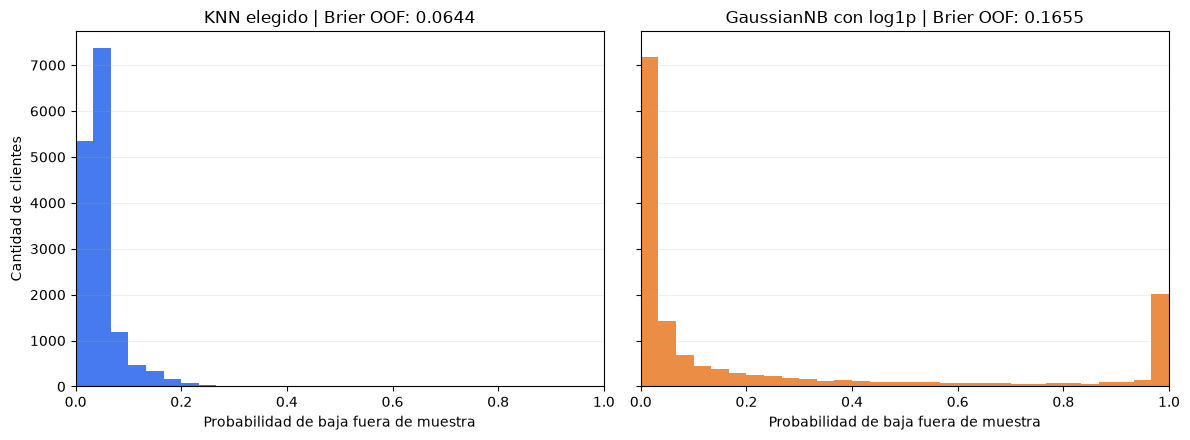

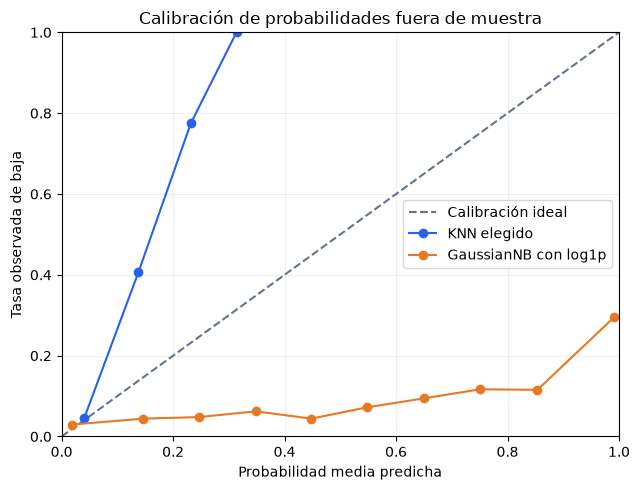

In [25]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.model_selection import cross_val_predict

# Una probabilidad por cliente, predicha sin usarlo en el ajuste de su fold.
# Cada clon vuelve a aprender todo el preprocesamiento dentro de ese fold.
modelos_paso14 = {'KNN elegido': mejor_knn, nombre_mejor_nb: mejor_nb}
probabilidades_oof = pd.DataFrame(index=X_train.index)
for nombre, modelo in modelos_paso14.items():
    probabilidades_oof[nombre] = cross_val_predict(
        clone(modelo), X_train, y_train, cv=particiones_paso12,
        method='predict_proba', n_jobs=1,
    )[:, 1]  # baja_90d: clases ordenadas [0, 1]

# Referencia constante: prevalencia aprendida sin el fold que se predice.
prob_referencia_oof = np.empty(len(y_train), dtype=float)
for indices_ajuste, indices_validacion in particiones_paso12:
    prob_referencia_oof[indices_validacion] = y_train.iloc[indices_ajuste].mean()

filas_paso14 = []
for nombre, prob in probabilidades_oof.items():
    riesgo_alto = prob >= 0.8
    filas_paso14.append({
        'Modelo': nombre,
        'Brier OOF (menor es mejor)': brier_score_loss(y_train, prob),
        'AP OOF': average_precision_score(y_train, prob),
        'Probabilidad media': prob.mean(),
        'Fracción p <= 0,05': (prob <= 0.05).mean(),
        'Fracción p >= 0,80': riesgo_alto.mean(),
        'Clientes p >= 0,80': riesgo_alto.sum(),
        'Probabilidad media p >= 0,80': prob[riesgo_alto].mean(),
        'Tasa real de baja p >= 0,80': y_train.loc[riesgo_alto].mean(),
    })
resumen_paso14 = pd.DataFrame(filas_paso14).set_index('Modelo')
display(resumen_paso14.round(4).T)
print(f'Brier de referencia constante OOF: {brier_score_loss(y_train, prob_referencia_oof):.4f}')
print(f'Tasa real de baja en entrenamiento: {y_train.mean():.4f}')

# Ambos histogramas usan los mismos intervalos y límites para compararlos.
fig_paso14, axes_paso14 = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
colores_paso14 = ['#2563eb', '#e87924']
for ax, (nombre, prob), color in zip(axes_paso14, probabilidades_oof.items(), colores_paso14):
    ax.hist(prob, bins=np.linspace(0, 1, 31), color=color, alpha=0.85)
    brier = brier_score_loss(y_train, prob)
    ax.set_title(f'{nombre} | Brier OOF: {brier:.4f}')
    ax.set_xlabel('Probabilidad de baja fuera de muestra')
    ax.set_xlim(0, 1)
    ax.grid(axis='y', alpha=0.2)
axes_paso14[0].set_ylabel('Cantidad de clientes')
fig_paso14.tight_layout()
fig_paso14.savefig('figuras/paso14_histogramas_oof.png', dpi=160, bbox_inches='tight')
plt.show()

# La curva permite contrastar confianza predicha y frecuencia observada.
# Los histogramas y el Brier solos no aíslan la calibración.
fig_calibracion, ax_calibracion = plt.subplots(figsize=(6.5, 5))
ax_calibracion.plot([0, 1], [0, 1], '--', color='#64748b', label='Calibración ideal')
calibracion_paso14 = {}
for (nombre, prob), color in zip(probabilidades_oof.items(), colores_paso14):
    tasa_observada, media_predicha = calibration_curve(
        y_train, prob, n_bins=10, strategy='uniform',
    )
    calibracion_paso14[nombre] = pd.DataFrame({
        'Probabilidad media': media_predicha, 'Tasa observada': tasa_observada,
    })
    ax_calibracion.plot(media_predicha, tasa_observada, 'o-', color=color, label=nombre)
ax_calibracion.set(xlabel='Probabilidad media predicha', ylabel='Tasa observada de baja',
                   title='Calibración de probabilidades fuera de muestra', xlim=(0, 1), ylim=(0, 1))
ax_calibracion.legend()
ax_calibracion.grid(alpha=0.2)
fig_calibracion.tight_layout()
fig_calibracion.savefig('figuras/paso14_calibracion_oof.png', dpi=160, bbox_inches='tight')
plt.show()

# Variables para elegir umbrales en la Parte E; el orden coincide con y_train.
prob_oof_knn = probabilidades_oof['KNN elegido'].to_numpy()
prob_oof_nb = probabilidades_oof[nombre_mejor_nb].to_numpy()

**Interpretación del Paso 14.** El Brier fuera de muestra es **0,0644 para KNN** y **0,1655 para GaussianNB con `log1p`**; cuanto menor, mejor. La referencia constante, calculada con la prevalencia del entrenamiento de cada fold, obtiene **0,0708**. KNN mejora esa referencia y GaussianNB la empeora, aunque GaussianNB sí ordena el riesgo mejor que una puntuación constante.

**GaussianNB exagera más su confianza.** Asigna probabilidades de al menos 0,80 a **2.472 clientes (16,48%)**. En ese grupo predice un promedio de **0,9791**, frente a una tasa observada de baja de **0,2791**. Su probabilidad media en toda la muestra es **0,2445**, muy por encima de la prevalencia real (**0,0767**). El histograma y los puntos por debajo de la diagonal de calibración respaldan esta sobreestimación; las dependencias del Paso 13 ofrecen una explicación posible, no una causa aislada demostrada.

KNN no asigna probabilidades de al menos 0,80; las dos medias de ese grupo aparecen como NaN porque no hay clientes. Su probabilidad media es **0,0490**, inferior a la prevalencia, por lo que también muestra subestimación del riesgo y un mejor Brier no implica calibración perfecta. El Brier combina calibración y capacidad de discriminar: la [documentación de calibración de scikit-learn](https://scikit-learn.org/stable/modules/calibration.html) explica esa distinción.

Las probabilidades OOF quedan disponibles como `prob_oof_knn` y `prob_oof_nb`, en el orden de `y_train`, para la elección de umbrales en la Parte E. El AP calculado sobre todas las predicciones OOF (0,4227 y 0,3526) difiere del promedio de AP de los cinco folds: son agregaciones distintas. Los hiperparámetros y la variante logarítmica se eligieron usando estas mismas particiones; esta evaluación no es validación anidada y puede ser optimista por la selección. La confirmación queda para la evaluación final de la Parte E.

## Parte E · Economía de la campaña (`src/negocio.py`)

**Paso 15.** Implementen las funciones de `src/negocio.py` hasta que pasen `tests/test_negocio.py`. Informen G⁺, G⁻ y la probabilidad de equilibrio.

In [ ]:
# Tu código aquí

**Paso 16.** Regla comercial sobre el conjunto de entrenamiento: clientes marcados, proporción que se fue y ganancia por cada 1.000 clientes.

In [ ]:
# Tu código aquí

**Paso 17.** Umbral de cada modelo con `mejor_umbral` sobre probabilidades fuera de muestra, con un máximo del 7% de los clientes. Comparación con la probabilidad de equilibrio.

In [ ]:
# Tu código aquí

**Paso 18.** Evaluación única en prueba: tabla de estrategias y curva de ganancia acumulada.

In [ ]:
# Tu código aquí

## Parte F · Explicación para Fidelización

**Paso 19.** Importancia por permutación del modelo elegido sobre prueba (`average_precision`).

In [ ]:
# Tu código aquí

**Paso 20.** Función `explicar_cliente(id_cliente)` y su aplicación a los 3 clientes de mayor riesgo de la campaña, con la oferta propuesta para cada uno.

In [ ]:
# Tu código aquí

## Parte G · Lista de la campaña de octubre

**Paso 21.** Reentrenen el modelo con todos los clientes residenciales del histórico y calculen la probabilidad de baja de `datos/clientes_campania.csv`.

In [ ]:
# Tu código aquí

**Paso 22.** Generen `campania_octubre.csv` (6.000 filas; columnas `id_cliente`, `prob_baja`, `contactar`) y verifiquen: como máximo 420 contactos, ningún empleado, ningún cliente repetido.

In [ ]:
# Tu código aquí

**Paso 23.** Ganancia esperada de la campaña con la precisión observada en prueba.

In [ ]:
# Tu código aquí

## Parte H · Informe ejecutivo

**Paso 24.** El informe para Martín Aquino se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. `motivo_baja` no puede ser variable del modelo, pero sí se usó para explicar a los vecinos. ¿Por qué un uso es incorrecto y el otro no?**

_Respuesta:_ 

**2. ¿Por qué KNN necesita estandarizar las variables y Naive Bayes gaussiano no?**

_Respuesta:_ 

**3. ¿Qué dice la diferencia entre el umbral elegido y la probabilidad de equilibrio sobre las probabilidades de KNN? ¿Qué le responderían a Finanzas?**

_Respuesta:_ 

**4. ¿Cómo medirían el efecto real de la campaña de octubre?**

_Respuesta:_ 

**5. ¿Es aceptable ofrecer descuentos solo a algunos clientes según su zona o su perfil? ¿Qué riesgos ven?**

_Respuesta:_ 

**6. ¿Qué implica que KNN guarde los datos de entrenamiento para actualizar el modelo y para la privacidad?**

_Respuesta:_ 

**7. ¿Qué pudo cambiar entre la foto de mayo y la de septiembre y cómo lo detectarían antes de lanzar la campaña?**

_Respuesta:_ 